# EN3150 Assignment 03 - RealWaste with TensorFlow/Keras



In [1]:
import os
import json
import time
import random
import shutil
import zipfile
import platform
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

print('Python:', platform.python_version())
print('TensorFlow:', tf.__version__)
print('Operating system:', platform.platform())
print('Visible GPUs:', tf.config.list_physical_devices('GPU'))
print('Working directory:', Path.cwd())


Python: 3.13.2
TensorFlow: 2.21.0
Operating system: Windows-11-10.0.26300-SP0
Visible GPUs: []
Working directory: d:\5th sem\PR\A03


In [ ]:
DATA_DIR = ''
DOWNLOAD_DATASET = True

IMAGE_SIZE = 64
SPLIT_SEED = 42
SEED = 42
BATCH_SIZE = 32

OUTPUT_DIR = Path('results') / 'tensorflow_results'

# Full assignment comparison:
MODELS_TO_RUN = ['Model A', 'Model B', 'MobileNetV2', 'EfficientNetB0']

# If you only want the strongest model first, use:
# MODELS_TO_RUN = ['EfficientNetB0']

CUSTOM_EPOCHS = 30
HEAD_EPOCHS = 12
FINE_TUNE_EPOCHS = 25

CUSTOM_LR = 1e-3
HEAD_LR = 1e-3
FINE_TUNE_LR = 1e-5
WEIGHT_DECAY = 1e-5
DROPOUT = 0.30

FINE_TUNE_LAST_N = {
    'MobileNetV2': 50,
    'EfficientNetB0': 80,
}

USE_TRANSFER_AUGMENTATION = True
RUN_OPTIMIZER_COMPARISON = False

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

# Prevent TensorFlow from reserving all GPU memory immediately.
for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception:
        pass


In [5]:
def find_realwaste_folder(root):
    root = Path(root)
    candidates = [
        root,
        root / 'realWaste',
        root / 'realwaste-main' / 'RealWaste',
    ]
    for candidate in candidates:
        if candidate.is_dir():
            class_dirs = [p for p in candidate.iterdir() if p.is_dir()]
            if len(class_dirs) == 9:
                return candidate
    return None


def resolve_realwaste_path(data_dir='', download=True):
    configured = os.environ.get('REALWASTE_DIR', data_dir).strip()

    if configured:
        found = find_realwaste_folder(Path(configured).expanduser())
        if found is None:
            raise FileNotFoundError(
                'DATA_DIR does not point to the RealWaste folder containing nine class folders.'
            )
        return found

    local_candidates = [
        Path.cwd() / 'data' / 'realwaste-main' / 'RealWaste',
        Path.cwd() / 'data' / 'RealWaste',
        Path.cwd().parent / 'data' / 'realwaste-main' / 'RealWaste',
    ]

    for candidate in local_candidates:
        if candidate.is_dir():
            return candidate

    if not download:
        raise FileNotFoundError(
            'RealWaste was not found. Set DATA_DIR or set DOWNLOAD_DATASET=True.'
        )

    data_root = Path.cwd() / 'data'
    data_root.mkdir(parents=True, exist_ok=True)
    archive = data_root / 'realwaste.zip'

    if not archive.exists():
        print('Downloading RealWaste from UCI...')
        temporary = data_root / 'realwaste.zip.part'
        urlretrieve(
            'https://archive.ics.uci.edu/static/public/908/realwaste.zip',
            temporary,
        )
        temporary.replace(archive)

    print('Extracting/checking RealWaste...')
    with zipfile.ZipFile(archive) as zf:
        root = data_root.resolve()
        for member in zf.infolist():
            target = (data_root / member.filename).resolve()
            if root not in target.parents and target != root:
                raise ValueError('Unsafe path detected in ZIP archive.')
        zf.extractall(data_root)

    found = find_realwaste_folder(data_root / 'realwaste-main')
    if found is None:
        found = find_realwaste_folder(data_root)
    if found is None:
        raise FileNotFoundError('Dataset was extracted but the RealWaste class folder was not found.')

    return found


DATA_PATH = resolve_realwaste_path(DATA_DIR, DOWNLOAD_DATASET)
print('RealWaste directory:', DATA_PATH.resolve())


Extracting/checking RealWaste...
RealWaste directory: D:\5th sem\PR\A03\data\realwaste-main\RealWaste


In [6]:
VALID_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.tif', '.tiff', '.webp'}

class_names = sorted([p.name for p in DATA_PATH.iterdir() if p.is_dir()])
class_to_index = {name: i for i, name in enumerate(class_names)}

all_paths = []
all_labels = []

for class_name in class_names:
    class_dir = DATA_PATH / class_name
    files = sorted(
        p for p in class_dir.rglob('*')
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )
    all_paths.extend([str(p) for p in files])
    all_labels.extend([class_to_index[class_name]] * len(files))

all_paths = np.asarray(all_paths)
all_labels = np.asarray(all_labels, dtype=np.int32)

if len(class_names) != 9:
    raise ValueError(f'Expected 9 classes, found {len(class_names)}: {class_names}')

if len(all_paths) != 4752:
    raise ValueError(f'Expected 4,752 images, found {len(all_paths)}')

indices = np.arange(len(all_paths))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SPLIT_SEED,
    stratify=all_labels,
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SPLIT_SEED,
    stratify=all_labels[temp_idx],
)

assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)

split_indices = {
    'train': train_idx.tolist(),
    'val': val_idx.tolist(),
    'test': test_idx.tolist(),
}

print('Classes:', class_names)
print('Total images:', len(all_paths))
print('Train:', len(train_idx))
print('Validation:', len(val_idx))
print('Test:', len(test_idx))

class_counts = pd.DataFrame({
    'class': class_names,
    'total': [int(np.sum(all_labels == i)) for i in range(len(class_names))],
    'train': [int(np.sum(all_labels[train_idx] == i)) for i in range(len(class_names))],
    'validation': [int(np.sum(all_labels[val_idx] == i)) for i in range(len(class_names))],
    'test': [int(np.sum(all_labels[test_idx] == i)) for i in range(len(class_names))],
})
class_counts


Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images: 4752
Train: 3326
Validation: 713
Test: 713


,class,total,train,validation,test
0,Cardboard,461,323,69,69
1,Food Organics,411,288,61,62
2,Glass,420,294,63,63
3,Metal,790,553,119,118
4,Miscellaneous Trash,495,346,74,75
5,Paper,500,350,75,75
6,Plastic,921,645,138,138
7,Textile Trash,318,222,48,48
8,Vegetation,436,305,66,65


In [7]:
AUTOTUNE = tf.data.AUTOTUNE


def decode_resize(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE],
        antialias=True,
    )
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.int32)


def make_dataset(indices_, training=False, seed=SEED):
    paths = all_paths[indices_]
    labels_ = all_labels[indices_]

    ds = tf.data.Dataset.from_tensor_slices((paths, labels_))
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()

    if training:
        ds = ds.shuffle(
            buffer_size=len(indices_),
            seed=seed,
            reshuffle_each_iteration=True,
        )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds


train_ds = make_dataset(train_idx, training=True)
val_ds = make_dataset(val_idx, training=False)
test_ds = make_dataset(test_idx, training=False)

for batch_images, batch_labels in train_ds.take(1):
    print('Image batch:', batch_images.shape)
    print('Label batch:', batch_labels.shape)
    print('Pixel range:', float(tf.reduce_min(batch_images)), 'to', float(tf.reduce_max(batch_images)))


Image batch: (32, 64, 64, 3)
Label batch: (32,)
Pixel range: 0.0 to 249.50897216796875


In [8]:
def make_transfer_augmentation():
    return keras.Sequential(
        [
            layers.RandomFlip('horizontal'),
            layers.RandomRotation(0.04, fill_mode='reflect'),
            layers.RandomZoom(
                height_factor=(-0.08, 0.08),
                width_factor=(-0.08, 0.08),
                fill_mode='reflect',
            ),
            layers.RandomContrast(0.08),
        ],
        name='transfer_augmentation',
    )


In [ ]:
# Model A: standard CNN
def build_model_a(num_classes):
    inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
    x = layers.Rescaling(1.0 / 255.0)(inputs)

    x = layers.Conv2D(16, 3, padding='same', activation='relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(32, 3, padding='same', activation='relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, padding='same', activation='relu')(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return keras.Model(inputs, outputs, name='Model_A')


# Model B: lightweight CNN
def depthwise_separable_block(x, filters, stride=1):
    x = layers.DepthwiseConv2D(
        3,
        strides=stride,
        padding='same',
        use_bias=False,
    )(x)
    x = layers.Conv2D(filters, 1, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x


def build_model_b(num_classes):
    inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
    x = layers.Rescaling(1.0 / 255.0)(inputs)

    x = layers.Conv2D(16, 3, strides=2, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = depthwise_separable_block(x, 32, stride=2)
    x = depthwise_separable_block(x, 64, stride=2)
    x = depthwise_separable_block(x, 64, stride=1)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs, name='Model_B')

    if model.count_params() > 100_000:
        raise ValueError('Model B exceeds 100,000 parameters.')
    return model


model_a_preview = build_model_a(len(class_names))
model_b_preview = build_model_b(len(class_names))
print('Model A parameters:', f'{model_a_preview.count_params():,}')
print('Model B parameters:', f'{model_b_preview.count_params():,}')


Model A parameters: 549,161
Model B parameters: 9,385


In [ ]:
# Transfer-learning models
def build_transfer_model(model_name, num_classes):
    inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), name='image')
    x = inputs

    if USE_TRANSFER_AUGMENTATION:
        x = make_transfer_augmentation()(x)

    if model_name == 'MobileNetV2':
        x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name='mobilenet_preprocess')(x)
        base_model = keras.applications.MobileNetV2(
            include_top=False,
            weights='imagenet',
            input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        )
    elif model_name == 'EfficientNetB0':
        # EfficientNetB0 already includes its input rescaling.
        base_model = keras.applications.EfficientNetB0(
            include_top=False,
            weights='imagenet',
            input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        )
    else:
        raise ValueError(f'Unknown transfer model: {model_name}')

    base_model.trainable = False
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation='swish')(x)
    x = layers.Dropout(DROPOUT)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs, name=model_name)
    return model, base_model


In [ ]:
# Training utilities
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_seconds = []

    def on_epoch_begin(self, epoch, logs=None):
        self._started = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_seconds.append(time.perf_counter() - self._started)


def make_optimizer(lr):
    try:
        return keras.optimizers.AdamW(
            learning_rate=lr,
            weight_decay=WEIGHT_DECAY,
        )
    except Exception:
        return keras.optimizers.Adam(learning_rate=lr)


def compile_model(model, lr):
    model.compile(
        optimizer=make_optimizer(lr),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
    )


def make_callbacks(checkpoint_path, early_stopping=True, patience=7):
    timer = EpochTimer()
    callbacks = [
        keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            monitor='val_accuracy',
            mode='max',
            save_best_only=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            mode='min',
            factor=0.5,
            patience=3,
            min_lr=1e-7,
            verbose=1,
        ),
        timer,
    ]

    if early_stopping:
        callbacks.insert(
            1,
            keras.callbacks.EarlyStopping(
                monitor='val_accuracy',
                mode='max',
                patience=patience,
                restore_best_weights=True,
                verbose=1,
            ),
        )

    return callbacks, timer


def merge_histories(*history_objects):
    merged = {}
    for history_obj in history_objects:
        for key, values in history_obj.history.items():
            merged.setdefault(key, []).extend([float(v) for v in values])
    return merged


def best_validation_from_history(history_obj):
    val_acc = np.asarray(history_obj.history['val_accuracy'], dtype=float)
    val_loss = np.asarray(history_obj.history['val_loss'], dtype=float)
    best_acc = float(np.max(val_acc))
    candidates = np.where(np.isclose(val_acc, best_acc))[0]
    best_index = int(candidates[np.argmin(val_loss[candidates])])
    return {
        'best_val_accuracy': best_acc,
        'best_val_loss': float(val_loss[best_index]),
        'best_epoch': best_index + 1,
    }


In [ ]:
# Evaluation and plots
def get_true_labels(ds):
    return np.concatenate([labels_.numpy() for _, labels_ in ds], axis=0)


def evaluate_and_export(model, model_name, history, checkpoint_path, training_details):
    slug = model_name.lower().replace(' ', '_').replace('-', '_')
    checkpoint_path = Path(checkpoint_path)

    probabilities = model.predict(test_ds, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    labels_true = get_true_labels(test_ds)

    report = classification_report(
        labels_true,
        predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
    matrix = confusion_matrix(
        labels_true,
        predictions,
        labels=list(range(len(class_names))),
    )

    metrics = {
        'model': model_name,
        'total_parameters': int(model.count_params()),
        'checkpoint_file_kib': float(checkpoint_path.stat().st_size / 1024),
        'epochs_completed': int(len(history['val_accuracy'])),
        'test_accuracy': float(accuracy_score(labels_true, predictions)),
        'weighted_precision': float(precision_score(labels_true, predictions, average='weighted', zero_division=0)),
        'weighted_recall': float(recall_score(labels_true, predictions, average='weighted', zero_division=0)),
        'weighted_f1': float(f1_score(labels_true, predictions, average='weighted', zero_division=0)),
        'macro_precision': float(precision_score(labels_true, predictions, average='macro', zero_division=0)),
        'macro_recall': float(recall_score(labels_true, predictions, average='macro', zero_division=0)),
        'macro_f1': float(f1_score(labels_true, predictions, average='macro', zero_division=0)),
        'training_details': training_details,
    }

    pd.DataFrame(report).transpose().to_csv(OUTPUT_DIR / f'{slug}_classification.csv')
    pd.DataFrame(matrix, index=class_names, columns=class_names).to_csv(
        OUTPUT_DIR / f'{slug}_confusion.csv'
    )

    with open(OUTPUT_DIR / f'{slug}_metrics.json', 'w', encoding='utf-8') as f:
        json.dump({**metrics, 'history': history, 'confusion_matrix': matrix.tolist()}, f, indent=2)

    epochs = np.arange(1, len(history['val_accuracy']) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history['loss'], label='Training')
    plt.plot(epochs, history['val_loss'], label='Validation')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f'{model_name}: loss')
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{slug}_loss.png', dpi=160)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, np.asarray(history['accuracy']) * 100, label='Training')
    plt.plot(epochs, np.asarray(history['val_accuracy']) * 100, label='Validation')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title(f'{model_name}: accuracy')
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{slug}_accuracy.png', dpi=160)
    plt.show()

    plt.figure(figsize=(10, 9))
    plt.imshow(matrix, cmap='Blues')
    plt.title(f'{model_name}: test confusion matrix')
    plt.xlabel('Predicted class')
    plt.ylabel('Actual class')
    plt.xticks(range(len(class_names)), class_names, rotation=45, ha='right')
    plt.yticks(range(len(class_names)), class_names)

    threshold = matrix.max() / 2 if matrix.size else 0
    for r in range(len(class_names)):
        for c in range(len(class_names)):
            plt.text(
                c,
                r,
                str(matrix[r, c]),
                ha='center',
                va='center',
                color='white' if matrix[r, c] > threshold else 'black',
            )

    plt.colorbar()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{slug}_confusion.png', dpi=160)
    plt.show()

    return metrics


In [ ]:
# Train Model A / Model B
def train_custom_model(model_name):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    if model_name == 'Model A':
        model = build_model_a(len(class_names))
    elif model_name == 'Model B':
        model = build_model_b(len(class_names))
    else:
        raise ValueError(model_name)

    compile_model(model, CUSTOM_LR)

    checkpoint_dir = OUTPUT_DIR / 'checkpoints'
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    checkpoint = checkpoint_dir / f"{model_name.lower().replace(' ', '_')}.keras"

    callbacks, timer = make_callbacks(
        checkpoint,
        early_stopping=False,
    )

    history_obj = model.fit(
        make_dataset(train_idx, training=True, seed=SEED),
        validation_data=val_ds,
        epochs=CUSTOM_EPOCHS,
        callbacks=callbacks,
        verbose=1,
    )

    best_info = best_validation_from_history(history_obj)
    model = keras.models.load_model(checkpoint, compile=False)

    history = {
        key: [float(v) for v in values]
        for key, values in history_obj.history.items()
    }

    details = {
        'pretrained': False,
        **best_info,
        'mean_epoch_seconds': float(np.mean(timer.epoch_seconds)),
    }

    return model, history, str(checkpoint), details


In [ ]:
# Two-stage transfer learning
def train_transfer_model(model_name):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model, base_model = build_transfer_model(model_name, len(class_names))

    checkpoint_dir = OUTPUT_DIR / 'checkpoints'
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    slug = model_name.lower().replace('-', '_')
    head_checkpoint = checkpoint_dir / f'{slug}_head_best.keras'
    fine_checkpoint = checkpoint_dir / f'{slug}_fine_best.keras'
    final_checkpoint = checkpoint_dir / f'{slug}.keras'

    # Stage 1: train classifier head only.
    compile_model(model, HEAD_LR)
    head_callbacks, head_timer = make_callbacks(
        head_checkpoint,
        early_stopping=True,
        patience=6,
    )

    head_history = model.fit(
        make_dataset(train_idx, training=True, seed=SEED),
        validation_data=val_ds,
        epochs=HEAD_EPOCHS,
        callbacks=head_callbacks,
        verbose=1,
    )
    head_info = best_validation_from_history(head_history)

    # Stage 2: fine-tune the upper part of the pretrained backbone.
    base_model.trainable = True
    last_n = FINE_TUNE_LAST_N[model_name]
    freeze_until = max(0, len(base_model.layers) - last_n)

    for layer in base_model.layers[:freeze_until]:
        layer.trainable = False

    # Freeze BatchNorm while fine-tuning to avoid damaging pretrained statistics.
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    compile_model(model, FINE_TUNE_LR)
    fine_callbacks, fine_timer = make_callbacks(
        fine_checkpoint,
        early_stopping=True,
        patience=8,
    )

    fine_history = model.fit(
        make_dataset(train_idx, training=True, seed=SEED + 1),
        validation_data=val_ds,
        epochs=FINE_TUNE_EPOCHS,
        callbacks=fine_callbacks,
        verbose=1,
    )
    fine_info = best_validation_from_history(fine_history)

    head_key = (head_info['best_val_accuracy'], -head_info['best_val_loss'])
    fine_key = (fine_info['best_val_accuracy'], -fine_info['best_val_loss'])

    if fine_key > head_key:
        selected_stage = 'fine_tune'
        selected_source = fine_checkpoint
    else:
        selected_stage = 'head'
        selected_source = head_checkpoint

    shutil.copy2(selected_source, final_checkpoint)
    selected_model = keras.models.load_model(final_checkpoint, compile=False)
    history = merge_histories(head_history, fine_history)

    details = {
        'pretrained': True,
        'selected_stage': selected_stage,
        'head_best_val_accuracy': head_info['best_val_accuracy'],
        'head_best_val_loss': head_info['best_val_loss'],
        'fine_tune_best_val_accuracy': fine_info['best_val_accuracy'],
        'fine_tune_best_val_loss': fine_info['best_val_loss'],
        'fine_tune_last_n_layers': int(last_n),
        'head_epochs_completed': len(head_history.history['val_accuracy']),
        'fine_tune_epochs_completed': len(fine_history.history['val_accuracy']),
        'mean_head_epoch_seconds': float(np.mean(head_timer.epoch_seconds)),
        'mean_fine_tune_epoch_seconds': float(np.mean(fine_timer.epoch_seconds)),
        'best_val_accuracy': float(max(
            head_info['best_val_accuracy'],
            fine_info['best_val_accuracy'],
        )),
    }

    return selected_model, history, str(final_checkpoint), details



Training: Model A

Epoch 1/30


c:\Users\SHAAHID AHAMED\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.2871 - loss: 1.9401
Epoch 1: val_accuracy improved from None to 0.37868, saving model to results\tensorflow_high_accuracy\checkpoints\model_a.keras

Epoch 1: finished saving model to results\tensorflow_high_accuracy\checkpoints\model_a.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.2871 - loss: 1.9401 - val_accuracy: 0.3787 - val_loss: 1.7571 - learning_rate: 0.0010
Epoch 2/30
102/104 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4498 - loss: 1.5296
Epoch 2: val_accuracy improved from 0.37868 to 0.51613, saving model to results\tensorflow_high_accuracy\checkpoints\model_a.keras

Epoch 2: finished saving model to results\tensorflow_high_accuracy\checkpoints\model_a.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.4507 - loss: 1.5275 - val_accuracy: 0.5161 - val_loss: 1.3914 - learning_rate: 0.0010
Epoch 3/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5274 - loss: 1.3271
Epoch 3: val_accura

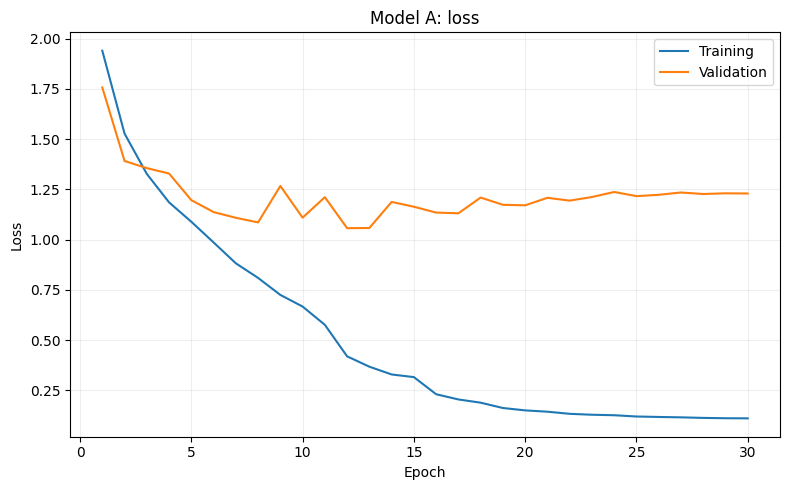

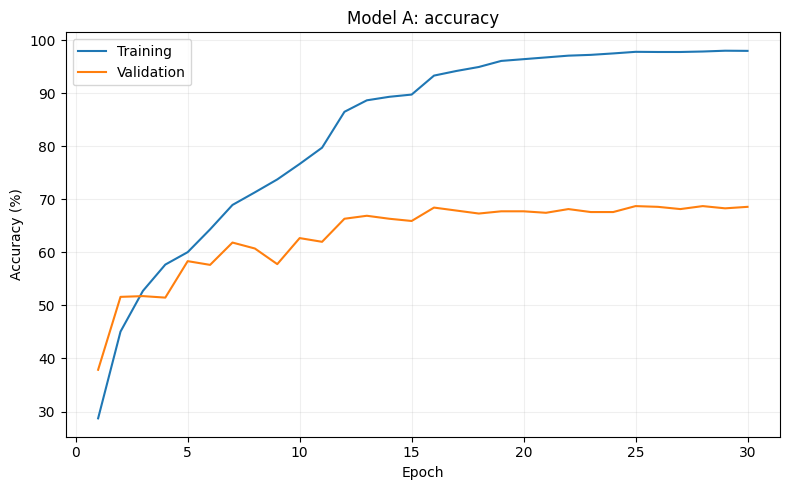

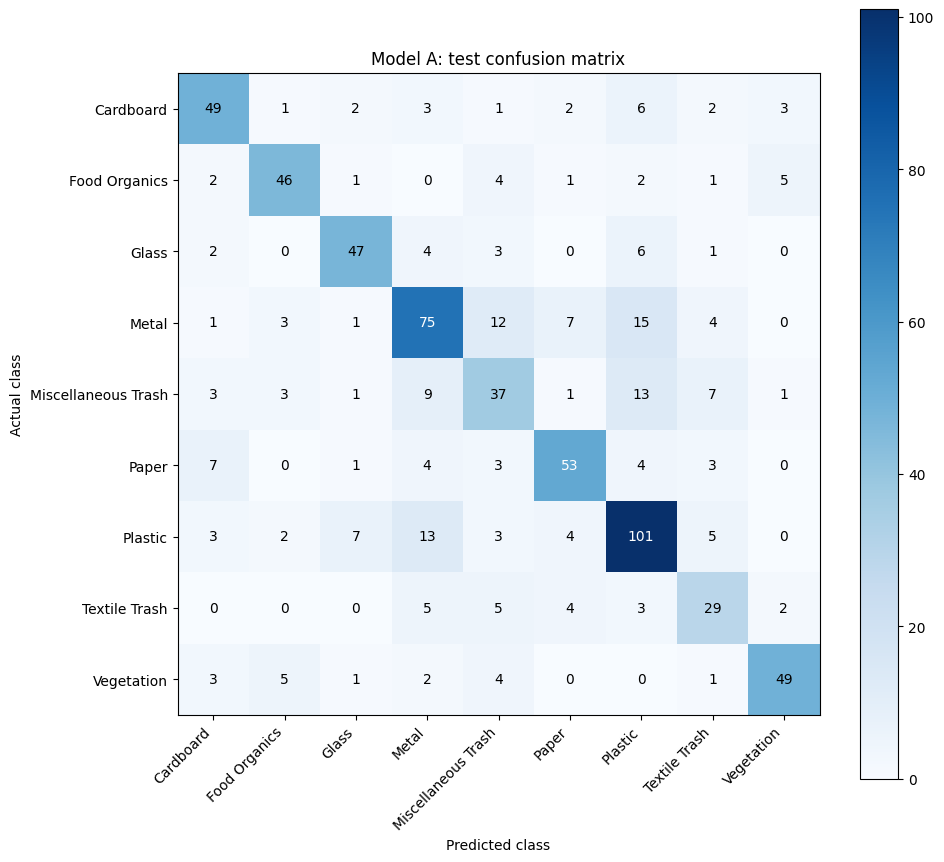


Training: Model B
Epoch 1/30


c:\Users\SHAAHID AHAMED\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


103/104 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3519 - loss: 1.8263
Epoch 1: val_accuracy improved from None to 0.19355, saving model to results\tensorflow_high_accuracy\checkpoints\model_b.keras

Epoch 1: finished saving model to results\tensorflow_high_accuracy\checkpoints\model_b.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - accuracy: 0.3527 - loss: 1.8247 - val_accuracy: 0.1935 - val_loss: 2.1632 - learning_rate: 0.0010
Epoch 2/30
103/104 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.4600 - loss: 1.5692
Epoch 2: val_accuracy did not improve from 0.19355
104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.4597 - loss: 1.5697 - val_accuracy: 0.1935 - val_loss: 2.1643 - learning_rate: 0.0010
Epoch 3/30
103/104 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5042 - loss: 1.4330
Epoch 3: val_accuracy did not improve from 0.19355
104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.5033 - loss: 1.4344 - val_accuracy: 0.1697 - val_loss: 2.3741 - learning_rate: 0.0010


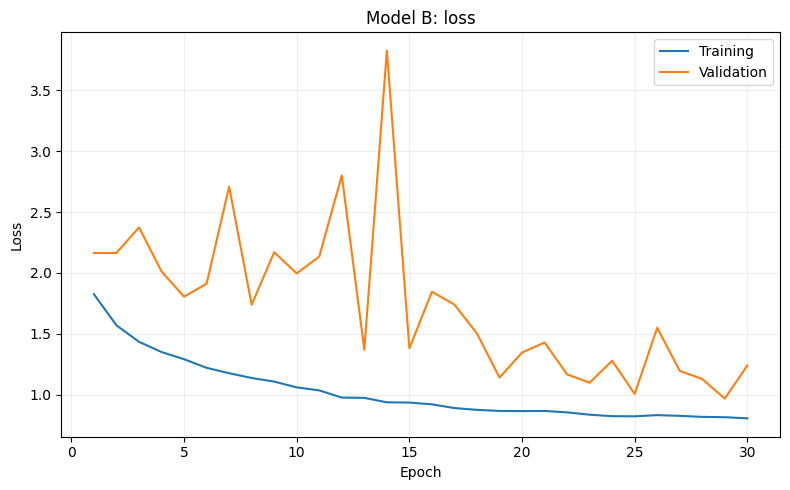

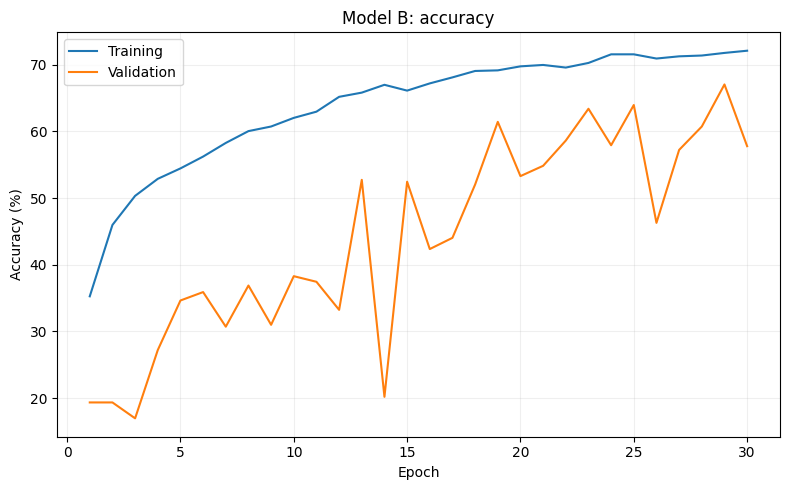

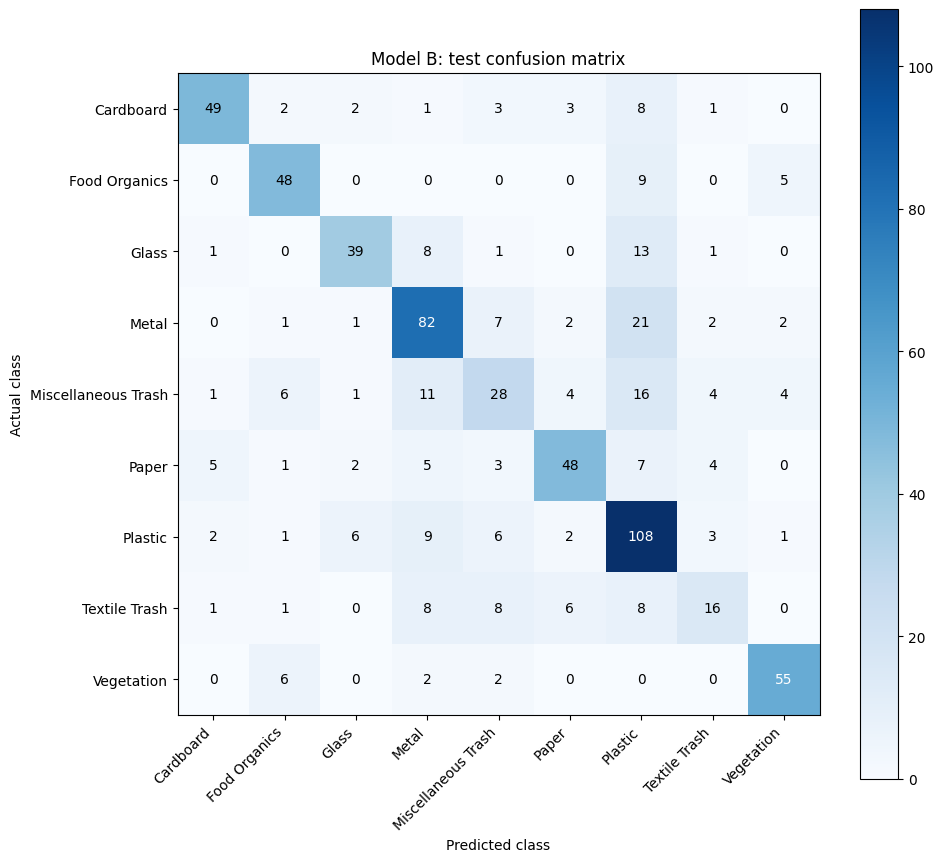


Training: MobileNetV2


C:\Users\SHAAHID AHAMED\AppData\Local\Temp\ipykernel_26792\2498188133.py:13: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(


Epoch 1/12


c:\Users\SHAAHID AHAMED\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.4928 - loss: 1.5991
Epoch 1: val_accuracy improved from None to 0.60589, saving model to results\tensorflow_high_accuracy\checkpoints\mobilenetv2_head_best.keras

Epoch 1: finished saving model to results\tensorflow_high_accuracy\checkpoints\mobilenetv2_head_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 191ms/step - accuracy: 0.4928 - loss: 1.5991 - val_accuracy: 0.6059 - val_loss: 1.2530 - learning_rate: 0.0010
Epoch 2/12
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.6368 - loss: 1.0503
Epoch 2: val_accuracy improved from 0.60589 to 0.63534, saving model to results\tensorflow_high_accuracy\checkpoints\mobilenetv2_head_best.keras

Epoch 2: finished saving model to results\tensorflow_high_accuracy\checkpoints\mobilenetv2_head_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 15s 145ms/step - accuracy: 0.6368 - loss: 1.0503 - val_accuracy: 0.6353 - val_loss: 1.1258 - learning_rate: 0.0010
Epoch 3/12
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 1

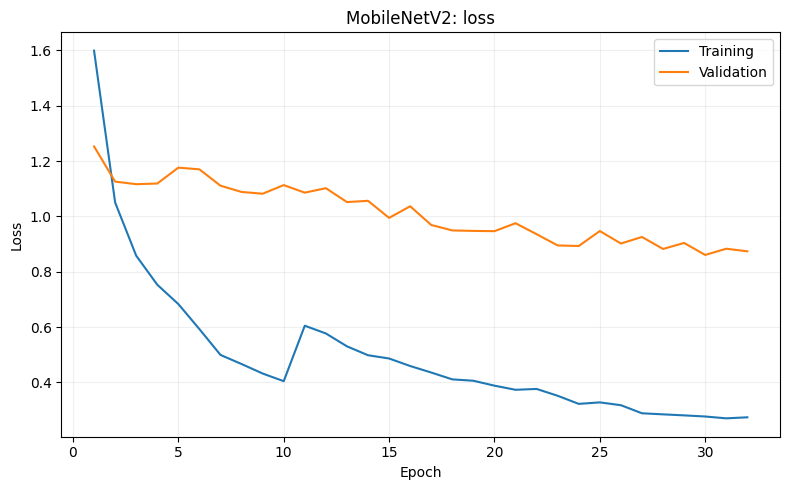

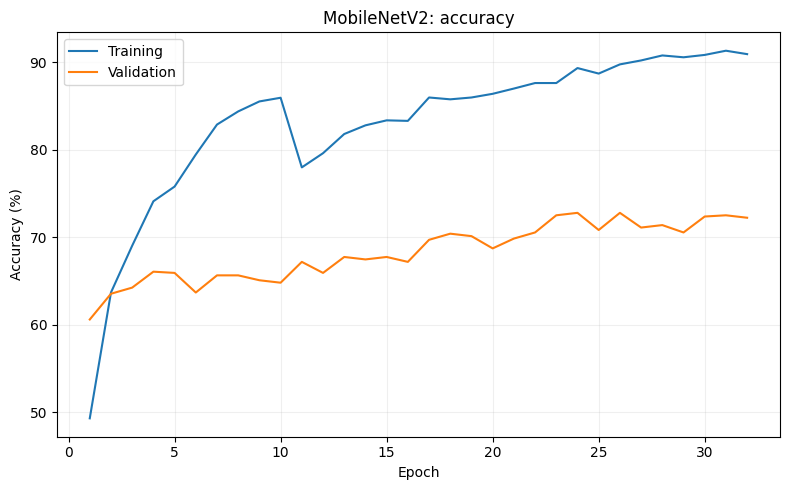

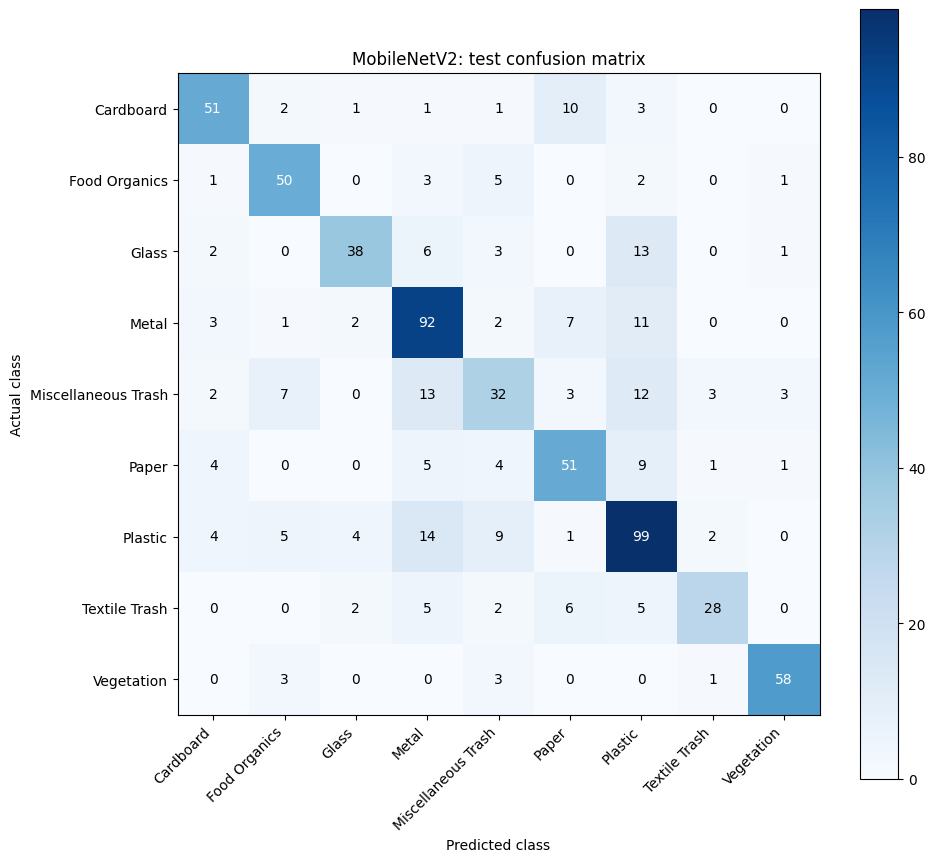


Training: EfficientNetB0
Epoch 1/12


c:\Users\SHAAHID AHAMED\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - accuracy: 0.5120 - loss: 1.5268
Epoch 1: val_accuracy improved from None to 0.63114, saving model to results\tensorflow_high_accuracy\checkpoints\efficientnetb0_head_best.keras

Epoch 1: finished saving model to results\tensorflow_high_accuracy\checkpoints\efficientnetb0_head_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 40s 288ms/step - accuracy: 0.5120 - loss: 1.5268 - val_accuracy: 0.6311 - val_loss: 1.1160 - learning_rate: 0.0010
Epoch 2/12
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.6843 - loss: 0.9089
Epoch 2: val_accuracy improved from 0.63114 to 0.67461, saving model to results\tensorflow_high_accuracy\checkpoints\efficientnetb0_head_best.keras

Epoch 2: finished saving model to results\tensorflow_high_accuracy\checkpoints\efficientnetb0_head_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 24s 228ms/step - accuracy: 0.6843 - loss: 0.9089 - val_accuracy: 0.6746 - val_loss: 0.9421 - learning_rate: 0.0010
Epoch 3/12
104/104 ━━━━━━━━━━━━━

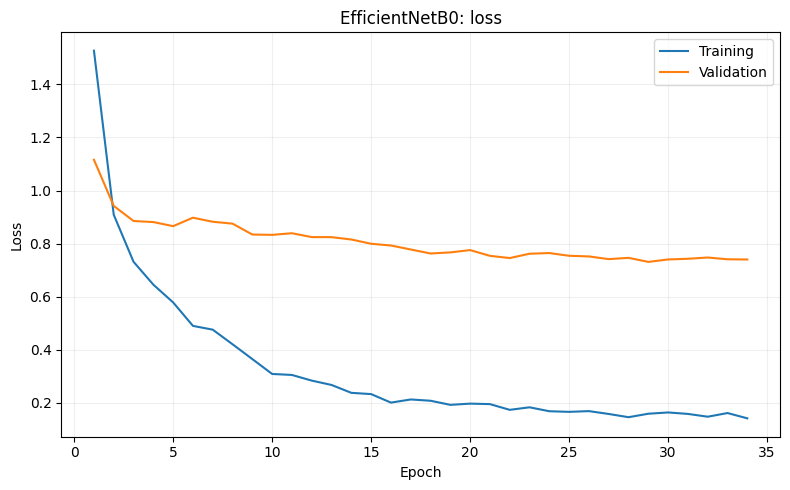

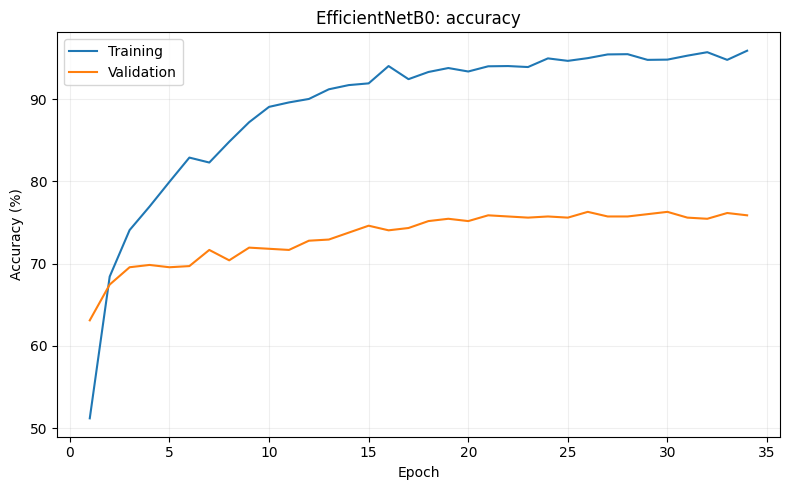

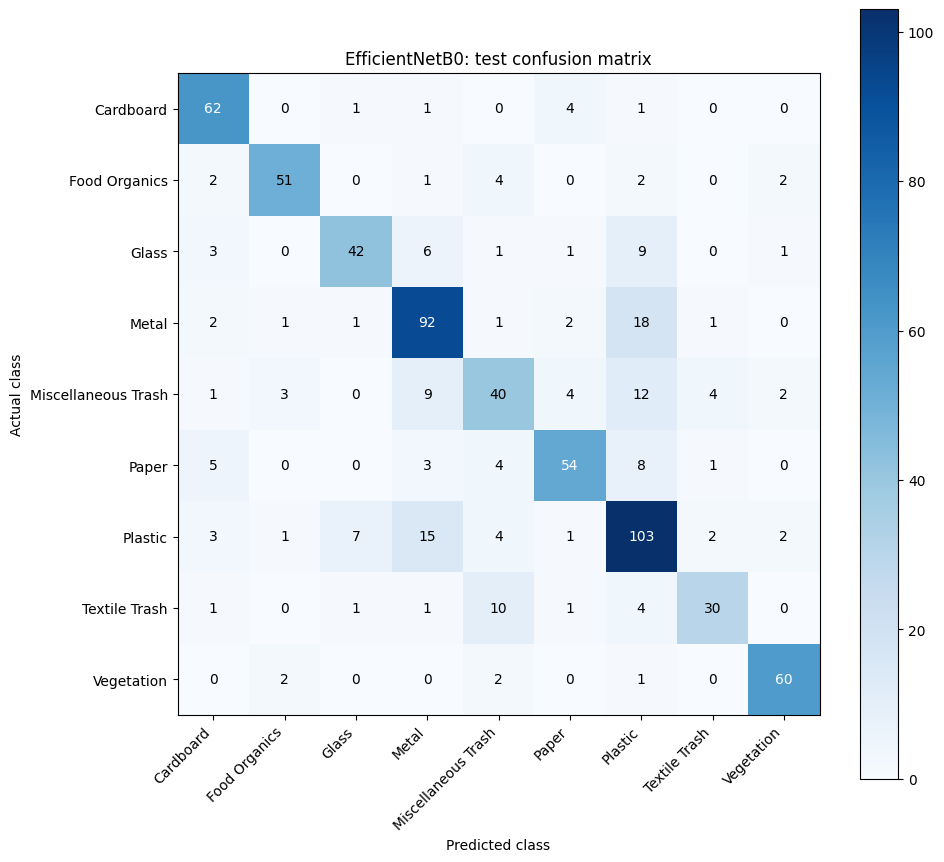

,model,total_parameters,checkpoint_file_kib,epochs_completed,test_accuracy,weighted_precision,weighted_recall,weighted_f1,macro_precision,macro_recall,macro_f1
0,EfficientNetB0,4384940,45651.230469,34,0.748948,0.752222,0.748948,0.747551,0.771054,0.746138,0.755210
1,MobileNetV2,2593353,27680.229492,32,0.699860,0.703437,0.699860,0.697274,0.721601,0.692013,0.701706
2,Model A,549161,6486.166992,30,0.681627,0.683518,0.681627,0.682017,0.686278,0.680400,0.682790
3,Model B,9385,192.884766,30,0.663394,0.666945,0.663394,0.658121,0.677772,0.641526,0.652852


In [15]:
# Run the selected models
all_results = []

experiment_record = {
    'dataset': 'RealWaste',
    'framework': 'TensorFlow/Keras',
    'tensorflow_version': tf.__version__,
    'image_size': IMAGE_SIZE,
    'classes': class_names,
    'split_seed': SPLIT_SEED,
    'split_sizes': {
        'train': len(train_idx),
        'validation': len(val_idx),
        'test': len(test_idx),
    },
    'split_indices': split_indices,
    'settings': {
        'models_to_run': MODELS_TO_RUN,
        'custom_epochs': CUSTOM_EPOCHS,
        'head_epochs': HEAD_EPOCHS,
        'fine_tune_epochs': FINE_TUNE_EPOCHS,
        'batch_size': BATCH_SIZE,
        'custom_lr': CUSTOM_LR,
        'head_lr': HEAD_LR,
        'fine_tune_lr': FINE_TUNE_LR,
        'weight_decay': WEIGHT_DECAY,
        'dropout': DROPOUT,
        'transfer_augmentation': USE_TRANSFER_AUGMENTATION,
    },
    'models': {},
}

for model_name in MODELS_TO_RUN:
    print()
    print('=' * 80)
    print('Training:', model_name)
    print('=' * 80)

    if model_name in {'Model A', 'Model B'}:
        model, history, checkpoint, details = train_custom_model(model_name)
    elif model_name in {'MobileNetV2', 'EfficientNetB0'}:
        model, history, checkpoint, details = train_transfer_model(model_name)
    else:
        raise ValueError(f'Unknown model: {model_name}')

    metrics = evaluate_and_export(
        model=model,
        model_name=model_name,
        history=history,
        checkpoint_path=checkpoint,
        training_details=details,
    )

    experiment_record['models'][model_name] = metrics
    all_results.append({
        key: value
        for key, value in metrics.items()
        if key != 'training_details'
    })

    with open(OUTPUT_DIR / 'experiment.json', 'w', encoding='utf-8') as f:
        json.dump(experiment_record, f, indent=2)

comparison = pd.DataFrame(all_results)
comparison = comparison.sort_values(
    by=['test_accuracy', 'weighted_f1'],
    ascending=False,
).reset_index(drop=True)

comparison.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)
comparison


In [16]:
# Compact final comparison
summary_columns = [
    'model',
    'test_accuracy',
    'weighted_precision',
    'weighted_recall',
    'weighted_f1',
    'total_parameters',
    'checkpoint_file_kib',
]

final_summary = comparison[summary_columns].copy()
for col in ['test_accuracy', 'weighted_precision', 'weighted_recall', 'weighted_f1']:
    final_summary[col] = (100 * final_summary[col]).round(2)

final_summary


,model,test_accuracy,weighted_precision,weighted_recall,weighted_f1,total_parameters,checkpoint_file_kib
0,EfficientNetB0,74.89,75.22,74.89,74.76,4384940,45651.230469
1,MobileNetV2,69.99,70.34,69.99,69.73,2593353,27680.229492
2,Model A,68.16,68.35,68.16,68.20,549161,6486.166992
3,Model B,66.34,66.69,66.34,65.81,9385,192.884766


## Optional optimizer comparison for Model B



In [18]:
# controlled optimizer comparison for Model B

def optimizer_from_config(config):
    if config['name'] == 'Adam':
        return keras.optimizers.Adam(learning_rate=config['lr'])

    return keras.optimizers.SGD(
        learning_rate=config['lr'],
        momentum=config['momentum'],
    )


def run_optimizer_comparison():
    configs = [
        {'name': 'Adam', 'lr': 0.001, 'momentum': 0.0},
        {'name': 'Adam', 'lr': 0.0003, 'momentum': 0.0},
        {'name': 'SGD', 'lr': 0.01, 'momentum': 0.0},
        {'name': 'SGD', 'lr': 0.1, 'momentum': 0.0},
        {'name': 'SGD + momentum', 'lr': 0.01, 'momentum': 0.9},
        {'name': 'SGD + momentum', 'lr': 0.1, 'momentum': 0.9},
    ]

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    template = build_model_b(len(class_names))
    initial_weights = template.get_weights()

    results = []
    optimizer_dir = OUTPUT_DIR / 'optimizer_comparison'
    optimizer_dir.mkdir(parents=True, exist_ok=True)

    for i, config in enumerate(configs, start=1):
        print()
        print('-' * 70)
        print(f'Optimizer trial {i}/{len(configs)}:', config)

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)

        model = build_model_b(len(class_names))
        model.set_weights(initial_weights)
        model.compile(
            optimizer=optimizer_from_config(config),
            loss=keras.losses.SparseCategoricalCrossentropy(),
            metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
        )

        checkpoint = optimizer_dir / f'trial_{i}.keras'
        history = model.fit(
            make_dataset(train_idx, training=True, seed=SEED),
            validation_data=val_ds,
            epochs=30,
            callbacks=[
                keras.callbacks.ModelCheckpoint(
                    checkpoint,
                    monitor='val_accuracy',
                    mode='max',
                    save_best_only=True,
                    verbose=0,
                )
            ],
            verbose=1,
        )

        info = best_validation_from_history(history)
        results.append({**config, **info, 'checkpoint': str(checkpoint)})

    result_df = pd.DataFrame(results)
    selected_index = (
        result_df.sort_values(
            by=['best_val_accuracy', 'best_val_loss'],
            ascending=[False, True],
        ).index[0]
    )

    selected = results[selected_index]
    selected_model = keras.models.load_model(selected['checkpoint'], compile=False)

    y_true = get_true_labels(test_ds)
    y_pred = np.argmax(selected_model.predict(test_ds, verbose=0), axis=1)

    print()
    print('Selected optimizer using validation only:')
    print(selected)
    print('Test accuracy:', accuracy_score(y_true, y_pred))
    print('Weighted F1:', f1_score(y_true, y_pred, average='weighted', zero_division=0))

    result_df.to_csv(optimizer_dir / 'optimizer_comparison.csv', index=False)
    return result_df, selected_model

RUN_OPTIMIZER_COMPARISON = True

if RUN_OPTIMIZER_COMPARISON:
    optimizer_results, selected_model_b = run_optimizer_comparison()
    optimizer_results
else:
    print('Optimizer comparison disabled. Set RUN_OPTIMIZER_COMPARISON=True to run it.')



----------------------------------------------------------------------
Optimizer trial 1/6: {'name': 'Adam', 'lr': 0.001, 'momentum': 0.0}
Epoch 1/30


c:\Users\SHAAHID AHAMED\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


104/104 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - accuracy: 0.3527 - loss: 1.8247 - val_accuracy: 0.1935 - val_loss: 2.1632
Epoch 2/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.4597 - loss: 1.5697 - val_accuracy: 0.1935 - val_loss: 2.1643
Epoch 3/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.5033 - loss: 1.4344 - val_accuracy: 0.1697 - val_loss: 2.3741
Epoch 4/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.5289 - loss: 1.3506 - val_accuracy: 0.2721 - val_loss: 2.0120
Epoch 5/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.5445 - loss: 1.2914 - val_accuracy: 0.3464 - val_loss: 1.8045
Epoch 6/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.5622 - loss: 1.2208 - val_accuracy: 0.3590 - val_loss: 1.9118
Epoch 7/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.5827 - loss: 1.1764 - val_accuracy: 0.3072 - val_loss: 2.7078
Epoch 8/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.6004 - loss: 1.1373 - val_accuracy: 0.368